In [9]:
# ============================================================
# CELL 1: INSTALL REQUIRED LIBRARIES
# ============================================================

!pip install -q tensorflow nltk pandas numpy matplotlib scikit-learn

In [10]:
# ============================================================
# CELL 2: IMPORT LIBRARIES
# ============================================================

import os
import re
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split

from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input,
    LSTM,
    Embedding,
    Dense
)

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

from nltk.translate.bleu_score import (
    corpus_bleu,
    sentence_bleu,
    SmoothingFunction
)

import nltk

# Download NLTK resources
nltk.download("punkt", quiet=True)

# Display TensorFlow version
print("TensorFlow Version:", tf.__version__)
print("NumPy Version:", np.__version__)
print("Pandas Version:", pd.__version__)

print("\nSetup Complete!")

TensorFlow Version: 2.20.0
NumPy Version: 2.1.3
Pandas Version: 2.2.3

Setup Complete!


In [11]:
# ============================================================
# UPLOAD ENGLISH-FRENCH DATASET
# ============================================================

from google.colab import files
import os
import zipfile

# Open upload window
uploaded = files.upload()

# Display uploaded files
print("\nUploaded files:")

for filename in uploaded.keys():
    print(filename)

Saving english_french.csv to english_french.csv

Uploaded files:
english_french.csv


In [13]:
# ============================================================
# CELL 8: INSPECT DATASET
# ============================================================

import pandas as pd

# Load the dataset into a DataFrame
df = pd.read_csv('english_french.csv')

print("Columns:")
print(df.columns.tolist())

print("\nDataset information:")
print(df.info())

print("\nFirst 10 rows:")
display(
    df.head(10)
)

Columns:
['English', 'French']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 229803 entries, 0 to 229802
Data columns (total 2 columns):
 #   Column   Non-Null Count   Dtype 
---  ------   --------------   ----- 
 0   English  229803 non-null  object
 1   French   229803 non-null  object
dtypes: object(2)
memory usage: 3.5+ MB
None

First 10 rows:


,English,French
0,Go.,Va !
1,Go.,Marche.
2,Go.,En route !
3,Go.,Bouge !
4,Hi.,Salut !
5,Hi.,Salut.
6,Run!,Cours !
7,Run!,Courez !
8,Run!,Prenez vos jambes à vos cous !
9,Run!,File !


In [14]:
# ============================================================
# CELL 9: IDENTIFY ENGLISH AND FRENCH COLUMNS
# ============================================================

english_column = None
french_column = None

for column in df.columns:

    column_name = str(
        column
    ).lower()

    # Look for English column
    if (
        "english" in column_name
        or column_name == "en"
    ):

        english_column = column

    # Look for French column
    if (
        "french" in column_name
        or column_name == "fr"
    ):

        french_column = column


print(
    "English column:",
    english_column
)

print(
    "French column:",
    french_column
)

English column: English
French column: French


In [15]:
# ============================================================
# CELL 10: CLEAN DATASET
# ============================================================

# If the automatic detection did not work,
# use the first two columns.
if english_column is None or french_column is None:

    print(
        "English/French columns were not automatically detected."
    )

    print(
        "Using the first two columns."
    )

    english_column = df.columns[0]
    french_column = df.columns[1]


# Create clean dataframe
data = df[
    [
        english_column,
        french_column
    ]
].copy()


# Rename columns
data.columns = [
    "english",
    "french"
]


# Remove missing values
data = data.dropna()


# Convert to string
data["english"] = (
    data["english"]
    .astype(str)
)

data["french"] = (
    data["french"]
    .astype(str)
)


# Remove duplicate pairs
data = data.drop_duplicates()


# Reset index
data = data.reset_index(
    drop=True
)


print(
    "Clean dataset shape:",
    data.shape
)

display(
    data.head(10)
)

Clean dataset shape: (229803, 2)


,english,french
0,Go.,Va !
1,Go.,Marche.
2,Go.,En route !
3,Go.,Bouge !
4,Hi.,Salut !
5,Hi.,Salut.
6,Run!,Cours !
7,Run!,Courez !
8,Run!,Prenez vos jambes à vos cous !
9,Run!,File !


In [16]:
# ============================================================
# CELL 11: SELECT DATASET SUBSET
# ============================================================

# Number of sentence pairs
MAX_SAMPLES = 30000

# Shuffle first
data = data.sample(
    n=min(
        MAX_SAMPLES,
        len(data)
    ),
    random_state=42
)

# Reset index
data = data.reset_index(
    drop=True
)

print(
    "Samples used:",
    len(data)
)

Samples used: 30000


In [17]:
# ============================================================
# CELL 12: TEXT CLEANING
# ============================================================

import re

def clean_text(text):

    text = str(text)

    # Convert to lowercase
    text = text.lower()

    # Remove unwanted characters
    text = re.sub(
        r"[^a-zA-ZÀ-ÿ0-9!?.,' ]",
        " ",
        text
    )

    # Remove multiple spaces
    text = re.sub(
        r"\s+",
        " ",
        text
    )

    # Remove leading/trailing spaces
    text = text.strip()

    return text


data["english"] = (
    data["english"]
    .apply(clean_text)
)

data["french"] = (
    data["french"]
    .apply(clean_text)
)


# Remove empty sentences
data = data[
    (data["english"].str.len() > 0)
    &
    (data["french"].str.len() > 0)
]


data = data.reset_index(
    drop=True
)


print(
    "Clean samples:",
    len(data)
)

display(
    data.head(10)
)

Clean samples: 30000


,english,french
0,"if you give me a book, i'll read it.","si vous me donnez un livre, je le lirai."
1,"we'll leave tomorrow, weather permitting.","nous partirons demain, si le temps le permet."
2,"i'm so happy, i feel like i could fly.",je suis si heureux que je m'élève dans le ciel.
3,pull over here.,arrêtez vous ici !
4,moses came down from the mountain bearing divi...,moïse descendit de la montagne en portant les ...
5,i appreciate your time.,je te suis reconnaissant pour ton temps.
6,what do you suggest?,que proposes tu ?
7,you're very fortunate.,vous avez vraiment beaucoup de chance.
8,what do you think about it? it'd be great!,qu'en pensez vous ? ce serait chouette !
9,this disease gradually leads to blindness.,cette maladie mène progressivement à la cécité.


In [18]:
# ============================================================
# CELL 13: ADD START AND END TOKENS
# ============================================================

data["french_input"] = (
    "<start> "
    + data["french"]
    + " <end>"
)

display(
    data[
        [
            "english",
            "french",
            "french_input"
        ]
    ].head()
)

,english,french,french_input
0,"if you give me a book, i'll read it.","si vous me donnez un livre, je le lirai.","<start> si vous me donnez un livre, je le lira..."
1,"we'll leave tomorrow, weather permitting.","nous partirons demain, si le temps le permet.","<start> nous partirons demain, si le temps le ..."
2,"i'm so happy, i feel like i could fly.",je suis si heureux que je m'élève dans le ciel.,<start> je suis si heureux que je m'élève dans...
3,pull over here.,arrêtez vous ici !,<start> arrêtez vous ici ! <end>
4,moses came down from the mountain bearing divi...,moïse descendit de la montagne en portant les ...,<start> moïse descendit de la montagne en port...


In [19]:
# ============================================================
# CELL 14: TRAIN-TEST SPLIT
# ============================================================

from sklearn.model_selection import train_test_split

train_data, test_data = train_test_split(
    data,
    test_size=0.10,
    random_state=42
)

train_data = train_data.reset_index(
    drop=True
)

test_data = test_data.reset_index(
    drop=True
)


print(
    "Training samples:",
    len(train_data)
)

print(
    "Testing samples:",
    len(test_data)
)

Training samples: 27000
Testing samples: 3000


In [20]:
# ============================================================
# CELL 15: ENGLISH TOKENIZER
# ============================================================

from tensorflow.keras.preprocessing.text import Tokenizer

MAX_VOCAB_SIZE = 15000

english_tokenizer = Tokenizer(
    num_words=MAX_VOCAB_SIZE,
    lower=True,
    oov_token="<unk>",
    filters=""
)


english_tokenizer.fit_on_texts(
    train_data["english"]
)


english_sequences = (
    english_tokenizer
    .texts_to_sequences(
        train_data["english"]
    )
)


MAX_ENCODER_LENGTH = min(
    max(
        len(sequence)
        for sequence in english_sequences
    ),
    30
)


ENCODER_VOCAB_SIZE = min(
    len(
        english_tokenizer.word_index
    ) + 1,
    MAX_VOCAB_SIZE
)


print(
    "English vocabulary:",
    ENCODER_VOCAB_SIZE
)

print(
    "Maximum English length:",
    MAX_ENCODER_LENGTH
)

English vocabulary: 11719
Maximum English length: 30


In [21]:
# ============================================================
# CELL 16: FRENCH TOKENIZER
# ============================================================

french_tokenizer = Tokenizer(
    num_words=MAX_VOCAB_SIZE,
    lower=True,
    oov_token="<unk>",
    filters=""
)


french_tokenizer.fit_on_texts(
    train_data["french_input"]
)


french_sequences = (
    french_tokenizer
    .texts_to_sequences(
        train_data["french_input"]
    )
)


MAX_DECODER_LENGTH = min(
    max(
        len(sequence)
        for sequence in french_sequences
    ),
    30
)


DECODER_VOCAB_SIZE = min(
    len(
        french_tokenizer.word_index
    ) + 1,
    MAX_VOCAB_SIZE
)


print(
    "French vocabulary:",
    DECODER_VOCAB_SIZE
)

print(
    "Maximum French length:",
    MAX_DECODER_LENGTH
)

French vocabulary: 15000
Maximum French length: 30


In [22]:
# ============================================================
# CELL 17: PREPARE MODEL INPUTS
# ============================================================

# English sequences
encoder_sequences = (
    english_tokenizer
    .texts_to_sequences(
        train_data["english"]
    )
)


# French sequences
decoder_sequences = (
    french_tokenizer
    .texts_to_sequences(
        train_data["french_input"]
    )
)


# Pad English
encoder_input_data = pad_sequences(
    encoder_sequences,
    maxlen=MAX_ENCODER_LENGTH,
    padding="post"
)


# Pad French
decoder_full_data = pad_sequences(
    decoder_sequences,
    maxlen=MAX_DECODER_LENGTH,
    padding="post"
)


# Decoder input
decoder_input_data = (
    decoder_full_data[:, :-1]
)


# Decoder target
decoder_target_data = (
    decoder_full_data[:, 1:]
)


print(
    "Encoder input:",
    encoder_input_data.shape
)

print(
    "Decoder input:",
    decoder_input_data.shape
)

print(
    "Decoder target:",
    decoder_target_data.shape
)

Encoder input: (27000, 30)
Decoder input: (27000, 29)
Decoder target: (27000, 29)


In [23]:
# ============================================================
# CELL 18: MODEL PARAMETERS
# ============================================================

EMBEDDING_DIM = 128

LATENT_DIM = 256

print(
    "Embedding dimension:",
    EMBEDDING_DIM
)

print(
    "Latent dimension:",
    LATENT_DIM
)

Embedding dimension: 128
Latent dimension: 256


In [24]:
# ============================================================
# CELL 19: ENCODER
# ============================================================

# English input
encoder_inputs = Input(
    shape=(MAX_ENCODER_LENGTH,),
    name="encoder_input"
)


# Word embeddings
encoder_embedding_layer = Embedding(
    input_dim=ENCODER_VOCAB_SIZE,
    output_dim=EMBEDDING_DIM,
    mask_zero=True,
    name="encoder_embedding"
)


encoder_embedding = (
    encoder_embedding_layer(
        encoder_inputs
    )
)


# Encoder LSTM
encoder_lstm = LSTM(
    LATENT_DIM,
    return_state=True,
    name="encoder_lstm"
)


encoder_outputs, state_h, state_c = (
    encoder_lstm(
        encoder_embedding
    )
)


# Latent representation
encoder_states = [
    state_h,
    state_c
]


print(
    "Encoder created successfully."
)

Encoder created successfully.


In [25]:
# ============================================================
# CELL 20: DECODER
# ============================================================

# Decoder input
decoder_inputs = Input(
    shape=(None,),
    name="decoder_input"
)


# French embedding
decoder_embedding_layer = Embedding(
    input_dim=DECODER_VOCAB_SIZE,
    output_dim=EMBEDDING_DIM,
    mask_zero=True,
    name="decoder_embedding"
)


decoder_embedding = (
    decoder_embedding_layer(
        decoder_inputs
    )
)


# Decoder LSTM
decoder_lstm = LSTM(
    LATENT_DIM,
    return_sequences=True,
    return_state=True,
    name="decoder_lstm"
)


decoder_outputs, _, _ = (
    decoder_lstm(
        decoder_embedding,
        initial_state=encoder_states
    )
)


# Output layer
decoder_dense = Dense(
    DECODER_VOCAB_SIZE,
    activation="softmax",
    name="decoder_output"
)


decoder_outputs = (
    decoder_dense(
        decoder_outputs
    )
)


print(
    "Decoder created successfully."
)

Decoder created successfully.


In [26]:
# ============================================================
# CELL 21: COMPLETE AUTOENCODER MODEL
# ============================================================

model = Model(
    [
        encoder_inputs,
        decoder_inputs
    ],
    decoder_outputs
)


model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input       │ (None, 30)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_input       │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_embedding   │ (None, 30, 128)   │  1,500,032 │ encoder_input[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 30)        │          0 │ encoder_input[0]… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_embedding   │ (None, None, 128) │  1,920,000 │ decoder_input[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_lstm (LSTM) │ [(None, 256),     │    394,240 │ encoder_embeddin… │
│                     │ (None, 256),      │            │ not_equal[0][0]   │
│                     │ (None, 256)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_lstm (LSTM) │ [(None, None,     │    394,240 │ decoder_embeddin… │
│                     │ 256), (None,      │            │ encoder_lstm[0][… │
│                     │ 256), (None,      │            │ encoder_lstm[0][… │
│                     │ 256)]             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_output      │ (None, None,      │  3,855,000 │ decoder_lstm[0][… │
│ (Dense)             │ 15000)            │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 8,063,512 (30.76 MB)

 Trainable params: 8,063,512 (30.76 MB)

 Non-trainable params: 0 (0.00 B)

In [27]:
# ============================================================
# CELL 22: COMPILE MODEL
# ============================================================

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


print(
    "Model compiled successfully!"
)

Model compiled successfully!


In [28]:
# ============================================================
# CELL 23: TRAIN MODEL
# ============================================================

EPOCHS = 15

BATCH_SIZE = 64


history = model.fit(

    [
        encoder_input_data,
        decoder_input_data
    ],

    decoder_target_data,

    batch_size=BATCH_SIZE,

    epochs=EPOCHS,

    validation_split=0.1,

    verbose=1
)

Epoch 1/15
380/380 ━━━━━━━━━━━━━━━━━━━━ 36s 78ms/step - accuracy: 0.2521 - loss: 5.4459 - val_accuracy: 0.2957 - val_loss: 4.5297
Epoch 2/15
380/380 ━━━━━━━━━━━━━━━━━━━━ 30s 78ms/step - accuracy: 0.3199 - loss: 4.4870 - val_accuracy: 0.3526 - val_loss: 4.0737
Epoch 3/15
380/380 ━━━━━━━━━━━━━━━━━━━━ 30s 78ms/step - accuracy: 0.3819 - loss: 3.9531 - val_accuracy: 0.4041 - val_loss: 3.6450
Epoch 4/15
380/380 ━━━━━━━━━━━━━━━━━━━━ 30s 79ms/step - accuracy: 0.4249 - loss: 3.5265 - val_accuracy: 0.4321 - val_loss: 3.3978
Epoch 5/15
380/380 ━━━━━━━━━━━━━━━━━━━━ 31s 80ms/step - accuracy: 0.4548 - loss: 3.2106 - val_accuracy: 0.4550 - val_loss: 3.2291
Epoch 6/15
380/380 ━━━━━━━━━━━━━━━━━━━━ 30s 80ms/step - accuracy: 0.4807 - loss: 2.9451 - val_accuracy: 0.4679 - val_loss: 3.0995
Epoch 7/15
380/380 ━━━━━━━━━━━━━━━━━━━━ 31s 80ms/step - accuracy: 0.5020 - loss: 2.7122 - val_accuracy: 0.4822 - val_loss: 3.0108
Epoch 8/15
380/380 ━━━━━━━━━━━━━━━━━━━━ 41s 81ms/step - accuracy: 0.5225 - loss: 2.5032 - 

In [29]:
# ============================================================
# TRAIN THE MODEL
# ============================================================

EPOCHS = 15
BATCH_SIZE = 64

history = model.fit(
    [encoder_input_data, decoder_input_data],
    decoder_target_data,
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    validation_split=0.1,
    verbose=1
)

print("Training completed successfully!")

Epoch 1/15
380/380 ━━━━━━━━━━━━━━━━━━━━ 30s 79ms/step - accuracy: 0.7026 - loss: 1.3147 - val_accuracy: 0.5295 - val_loss: 2.8043
Epoch 2/15
380/380 ━━━━━━━━━━━━━━━━━━━━ 30s 80ms/step - accuracy: 0.7245 - loss: 1.2129 - val_accuracy: 0.5345 - val_loss: 2.8213
Epoch 3/15
380/380 ━━━━━━━━━━━━━━━━━━━━ 41s 80ms/step - accuracy: 0.7456 - loss: 1.1184 - val_accuracy: 0.5347 - val_loss: 2.8444
Epoch 4/15
380/380 ━━━━━━━━━━━━━━━━━━━━ 30s 80ms/step - accuracy: 0.7645 - loss: 1.0337 - val_accuracy: 0.5355 - val_loss: 2.8510
Epoch 5/15
380/380 ━━━━━━━━━━━━━━━━━━━━ 41s 79ms/step - accuracy: 0.7838 - loss: 0.9515 - val_accuracy: 0.5390 - val_loss: 2.8655
Epoch 6/15
380/380 ━━━━━━━━━━━━━━━━━━━━ 41s 80ms/step - accuracy: 0.8002 - loss: 0.8775 - val_accuracy: 0.5387 - val_loss: 2.9015
Epoch 7/15
380/380 ━━━━━━━━━━━━━━━━━━━━ 30s 79ms/step - accuracy: 0.8165 - loss: 0.8098 - val_accuracy: 0.5387 - val_loss: 2.9340
Epoch 8/15
380/380 ━━━━━━━━━━━━━━━━━━━━ 30s 80ms/step - accuracy: 0.8323 - loss: 0.7449 - 

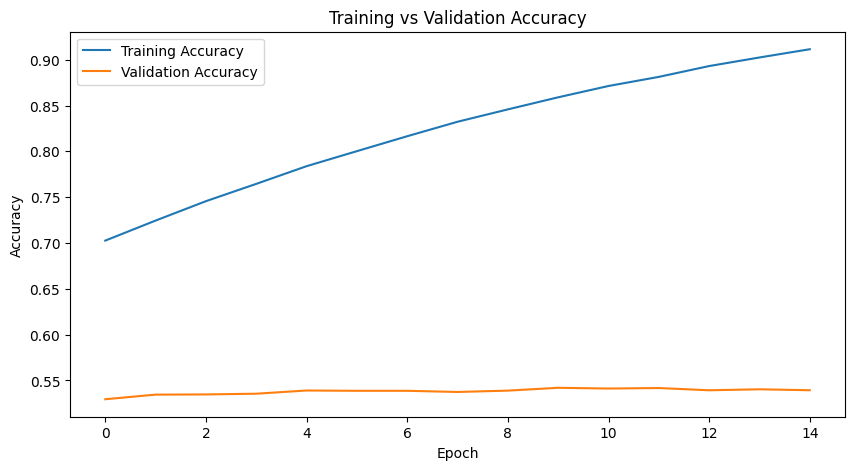

In [30]:
# ============================================================
# CELL 25: TRAINING ACCURACY
# ============================================================

plt.figure(
    figsize=(10, 5)
)

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.title(
    "Training vs Validation Accuracy"
)

plt.legend()

plt.show()

In [31]:
# ============================================================
# CELL 26: INFERENCE ENCODER
# ============================================================

encoder_model = Model(
    encoder_inputs,
    encoder_states
)


print(
    "Inference encoder created."
)

Inference encoder created.


In [32]:
# ============================================================
# CELL 27: INFERENCE DECODER
# ============================================================

decoder_state_input_h = Input(
    shape=(LATENT_DIM,)
)

decoder_state_input_c = Input(
    shape=(LATENT_DIM,)
)


decoder_states_inputs = [
    decoder_state_input_h,
    decoder_state_input_c
]


decoder_single_input = Input(
    shape=(1,)
)


decoder_single_embedding = (
    decoder_embedding_layer(
        decoder_single_input
    )
)


decoder_single_output, state_h_inf, state_c_inf = (
    decoder_lstm(
        decoder_single_embedding,
        initial_state=decoder_states_inputs
    )
)


decoder_single_output = (
    decoder_dense(
        decoder_single_output
    )
)


decoder_model = Model(

    [
        decoder_single_input,
        decoder_state_input_h,
        decoder_state_input_c
    ],

    [
        decoder_single_output,
        state_h_inf,
        state_c_inf
    ]
)


print(
    "Inference decoder created."
)

Inference decoder created.


In [33]:
# ============================================================
# CELL 28: REVERSE VOCABULARY
# ============================================================

reverse_french_word_index = {
    index: word
    for word, index
    in french_tokenizer.word_index.items()
}


START_TOKEN = (
    french_tokenizer
    .word_index["<start>"]
)

END_TOKEN = (
    french_tokenizer
    .word_index["<end>"]
)


print(
    "START token:",
    START_TOKEN
)

print(
    "END token:",
    END_TOKEN
)

START token: 2
END token: 3


In [34]:
# ============================================================
# CELL 29: ENGLISH → FRENCH TRANSLATION FUNCTION
# ============================================================

def translate_sentence(
    sentence
):

    # ----------------------------------------
    # Step 1: Clean sentence
    # ----------------------------------------

    sentence = clean_text(
        sentence
    )


    # ----------------------------------------
    # Step 2: Convert English to numbers
    # ----------------------------------------

    sequence = (
        english_tokenizer
        .texts_to_sequences(
            [sentence]
        )
    )


    # ----------------------------------------
    # Step 3: Pad sequence
    # ----------------------------------------

    sequence = pad_sequences(
        sequence,
        maxlen=MAX_ENCODER_LENGTH,
        padding="post"
    )


    # ----------------------------------------
    # Step 4: Encode English sentence
    # ----------------------------------------

    states = (
        encoder_model.predict(
            sequence,
            verbose=0
        )
    )


    # ----------------------------------------
    # Step 5: Start decoder
    # ----------------------------------------

    target_token = np.array(
        [[START_TOKEN]]
    )


    translated_words = []


    # ----------------------------------------
    # Step 6: Generate French words
    # ----------------------------------------

    for _ in range(
        MAX_DECODER_LENGTH
    ):

        output_tokens, h, c = (
            decoder_model.predict(
                [
                    target_token,
                    states[0],
                    states[1]
                ],
                verbose=0
            )
        )


        # Select most probable word
        sampled_token_index = (
            np.argmax(
                output_tokens[0, -1, :]
            )
        )


        # Stop at END token
        if (
            sampled_token_index
            == END_TOKEN
        ):
            break


        # Convert number to word
        sampled_word = (
            reverse_french_word_index
            .get(
                sampled_token_index,
                ""
            )
        )


        # Add word
        if (
            sampled_word
            not in [
                "",
                "<start>",
                "<end>"
            ]
        ):

            translated_words.append(
                sampled_word
            )


        # Feed predicted word
        # back into decoder
        target_token = np.array(
            [[sampled_token_index]]
        )


        # Update decoder states
        states = [
            h,
            c
        ]


    return " ".join(
        translated_words
    )

In [35]:
# ============================================================
# CELL 30: TEST TRANSLATION
# ============================================================

test_sentences = [

    "Hello.",

    "How are you?",

    "I am happy.",

    "I love you.",

    "Good morning.",

    "Thank you.",

    "What is your name?"

]


for sentence in test_sentences:

    translation = (
        translate_sentence(
            sentence
        )
    )

    print(
        "English :",
        sentence
    )

    print(
        "French  :",
        translation
    )

    print(
        "-" * 60
    )

English : Hello.
French  : salut !
------------------------------------------------------------
English : How are you?
French  : comment vas tu ?
------------------------------------------------------------
English : I am happy.
French  : je suis certain.
------------------------------------------------------------
English : I love you.
French  : je vous admire.
------------------------------------------------------------
English : Good morning.
French  : bien bien !
------------------------------------------------------------
English : Thank you.
French  : merci !
------------------------------------------------------------
English : What is your name?
French  : quel est ton nom ?
------------------------------------------------------------


In [36]:
# ============================================================
# CELL 31: TEST REAL DATASET EXAMPLES
# ============================================================

sample_test = test_data.sample(
    10,
    random_state=42
)


for _, row in sample_test.iterrows():

    english_sentence = (
        row["english"]
    )

    actual_french = (
        row["french"]
    )

    predicted_french = (
        translate_sentence(
            english_sentence
        )
    )


    print(
        "English   :",
        english_sentence
    )

    print(
        "Actual    :",
        actual_french
    )

    print(
        "Predicted :",
        predicted_french
    )

    print(
        "=" * 80
    )

English   : tom says that he needs to talk to you.
Actual    : tom dit qu'il a besoin de te parler.
Predicted : tom dit qu'il est venu à tom.
English   : there is little, if any, hope of his recovery.
Actual    : il y a un faible espoir, si jamais il y en a un, qu'il guérisse.
Predicted : il y a quelque chose dans son point qui est très fatigué.
English   : i want you to beg for mercy.
Actual    : je veux que tu implores grâce.
Predicted : je veux que vous alliez le week end.
English   : this bread is too expensive.
Actual    : ce pain coûte trop cher.
Predicted : ce chien ne fait pas trop cher.
English   : should i study french?
Actual    : dois je étudier le français ?
Predicted : devrais je venir au français ?
English   : she means nothing to him.
Actual    : elle ne signifie rien pour lui.
Predicted : elle sera à ce que je suis à la journée.
English   : can i borrow it for about two weeks?
Actual    : puis je l'emprunter pour deux semaines environ ?
Predicted : puis je emprunter la

In [37]:
# ============================================================
# CELL 32: BLEU SCORE
# ============================================================

references = []

hypotheses = []


smooth = (
    SmoothingFunction()
    .method1
)


# Number of examples for BLEU
BLEU_SAMPLES = min(
    500,
    len(test_data)
)


for i in range(
    BLEU_SAMPLES
):

    english_sentence = (
        test_data.iloc[i]["english"]
    )

    actual_french = (
        test_data.iloc[i]["french"]
    )


    # Generate translation
    predicted_french = (
        translate_sentence(
            english_sentence
        )
    )


    # Tokenize reference
    reference_tokens = (
        actual_french
        .lower()
        .split()
    )


    # Tokenize prediction
    hypothesis_tokens = (
        predicted_french
        .lower()
        .split()
    )


    # Ignore empty predictions
    if len(
        hypothesis_tokens
    ) == 0:

        continue


    references.append(
        [
            reference_tokens
        ]
    )

    hypotheses.append(
        hypothesis_tokens
    )


# Calculate BLEU
bleu_score = corpus_bleu(

    references,

    hypotheses,

    weights=(
        0.25,
        0.25,
        0.25,
        0.25
    ),

    smoothing_function=smooth
)


print(
    "Number of evaluated sentences:",
    len(hypotheses)
)

print(
    "BLEU Score:",
    bleu_score
)

print(
    "BLEU Score (%):",
    bleu_score * 100
)

Number of evaluated sentences: 500
BLEU Score: 0.13809020381982884
BLEU Score (%): 13.809020381982883


In [38]:
# ============================================================
# CELL 33: INDIVIDUAL BLEU SCORES
# ============================================================

individual_scores = []


for reference, hypothesis in zip(
    references,
    hypotheses
):

    score = sentence_bleu(

        reference,

        hypothesis,

        weights=(
            0.25,
            0.25,
            0.25,
            0.25
        ),

        smoothing_function=smooth
    )


    individual_scores.append(
        score
    )


average_bleu = np.mean(
    individual_scores
)


print(
    "Average Sentence BLEU:",
    average_bleu
)

print(
    "Average Sentence BLEU (%):",
    average_bleu * 100
)

Average Sentence BLEU: 0.13787207679117575
Average Sentence BLEU (%): 13.787207679117575


In [39]:
# ============================================================
# CELL 34: FINAL EVALUATION
# ============================================================

print()
print("=" * 70)
print("FINAL MODEL EVALUATION")
print("=" * 70)

print(
    "Dataset samples used:",
    len(data)
)

print(
    "Training samples:",
    len(train_data)
)

print(
    "Testing samples:",
    len(test_data)
)

print(
    "English vocabulary:",
    ENCODER_VOCAB_SIZE
)

print(
    "French vocabulary:",
    DECODER_VOCAB_SIZE
)

print(
    "Embedding dimension:",
    EMBEDDING_DIM
)

print(
    "Latent dimension:",
    LATENT_DIM
)

print(
    "Epochs:",
    EPOCHS
)

print(
    "Batch size:",
    BATCH_SIZE
)

print(
    "Final training accuracy:",
    history.history["accuracy"][-1]
)

print(
    "Final validation accuracy:",
    history.history["val_accuracy"][-1]
)

print(
    "BLEU Score:",
    bleu_score
)

print(
    "BLEU Score (%):",
    bleu_score * 100
)

print("=" * 70)


FINAL MODEL EVALUATION
Dataset samples used: 30000
Training samples: 27000
Testing samples: 3000
English vocabulary: 11719
French vocabulary: 15000
Embedding dimension: 128
Latent dimension: 256
Epochs: 15
Batch size: 64
Final training accuracy: 0.9114776253700256
Final validation accuracy: 0.5393068194389343
BLEU Score: 0.13809020381982884
BLEU Score (%): 13.809020381982883


In [40]:
# ============================================================
# CELL 35: SAVE MODEL
# ============================================================

model.save(
    "English_French_Autoencoder.keras"
)

print(
    "Model saved as:"
)

print(
    "English_French_Autoencoder.keras"
)

Model saved as:
English_French_Autoencoder.keras


In [41]:
# ============================================================
# CELL 36: FINAL DEMONSTRATION
# ============================================================

print()
print("=" * 70)
print("ENGLISH → FRENCH AUTOENCODER")
print("=" * 70)


sentences = [

    "Hello.",

    "How are you?",

    "I am happy.",

    "I love you.",

    "Good morning.",

    "Thank you.",

    "What is your name?"

]


for sentence in sentences:

    result = (
        translate_sentence(
            sentence
        )
    )


    print(
        f"\nEnglish : {sentence}"
    )

    print(
        f"French  : {result}"
    )


print()
print("=" * 70)
print("TRANSLATION COMPLETE")
print("=" * 70)


ENGLISH → FRENCH AUTOENCODER

English : Hello.
French  : salut !

English : How are you?
French  : comment vas tu ?

English : I am happy.
French  : je suis certain.

English : I love you.
French  : je vous admire.

English : Good morning.
French  : bien bien !

English : Thank you.
French  : merci !

English : What is your name?
French  : quel est ton nom ?

TRANSLATION COMPLETE
